In [3]:
import pandas as pd
train = pd.read_csv("ag_news_train.csv")
test = pd.read_csv("ag_news_test.csv")
print(train.shape)
print(train.head())

(8000, 2)
                                                text     label
0  Red Hat Appoints New CFO. September 2, 2004 --...  Sci_Tech
1  Sprint, SBC In Hotspot Roaming Deal. Sprint an...  Sci_Tech
2  Radio Outage Grounds West Coast Flights. Airpo...  Business
3  Hollywood lawsuits to strike Net pirates. Holl...  Sci_Tech
4  Custis Takes Control. Family and Tony Robbins ...    Sports


In [7]:
import pandas as pd
train = pd.read_csv("ag_news_train.csv")
test = pd.read_csv("ag_news_test.csv")
print(train.shape)
print(train.head())

(8000, 2)
                                                text     label
0  Red Hat Appoints New CFO. September 2, 2004 --...  Sci_Tech
1  Sprint, SBC In Hotspot Roaming Deal. Sprint an...  Sci_Tech
2  Radio Outage Grounds West Coast Flights. Airpo...  Business
3  Hollywood lawsuits to strike Net pirates. Holl...  Sci_Tech
4  Custis Takes Control. Family and Tony Robbins ...    Sports


In [8]:
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 75.4 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [29]:
import re, spacy
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])

import html

import html

def clean_text(t):
    t = html.unescape(html.unescape(t))
    t = re.sub(r"<[^>]+>", " ", t)
    t = re.sub(r"\\", " ", t)
    t = re.sub(r"&?#\d+;|\b(quot|amp|lt|gt);", " ", t)
    t = re.sub(r"http\S+|www\.\S+", " ", t)
    t = re.sub(r"\b[\w-]+\.(com|org|net)\b", " ", t)   # dominios
    t = t.lower()
    t = re.sub(r"quote,?\s*profile,?\s*research", " ", t)
    t = re.sub(r"[^a-z0-9\s]", " ", t)
    t = re.sub(r"\b(ap|afp|reuters?)\b", " ", t)       # agencias
    return re.sub(r"\s+", " ", t).strip()

def preprocess_corpus(texts):
    cleaned = (clean_text(t) for t in texts)
    return [" ".join(tok.lemma_ for tok in d if not tok.is_space)
            for d in nlp.pipe(cleaned, batch_size=500)]

In [30]:
train["clean"] = preprocess_corpus(train["text"])
test["clean"] = preprocess_corpus(test["text"])
print(train[["text", "clean"]].head())

                                                text  \
0  Red Hat Appoints New CFO. September 2, 2004 --...   
1  Sprint, SBC In Hotspot Roaming Deal. Sprint an...   
2  Radio Outage Grounds West Coast Flights. Airpo...   
3  Hollywood lawsuits to strike Net pirates. Holl...   
4  Custis Takes Control. Family and Tony Robbins ...   

                                               clean  
0  red hat appoint new cfo september 2 2004 web h...  
1  sprint sbc in hotspot roam deal sprint and sbc...  
2  radio outage ground west coast flights airport...  
3  hollywood lawsuit to strike net pirate hollywo...  
4  custis take control family and tony robbin hav...  


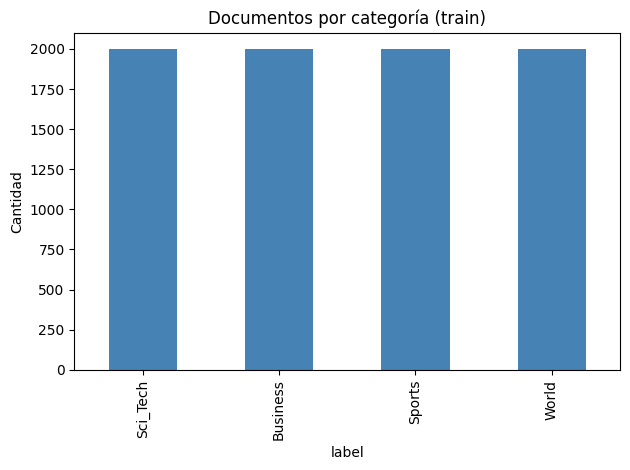

Percentil 95 (max_len): 53


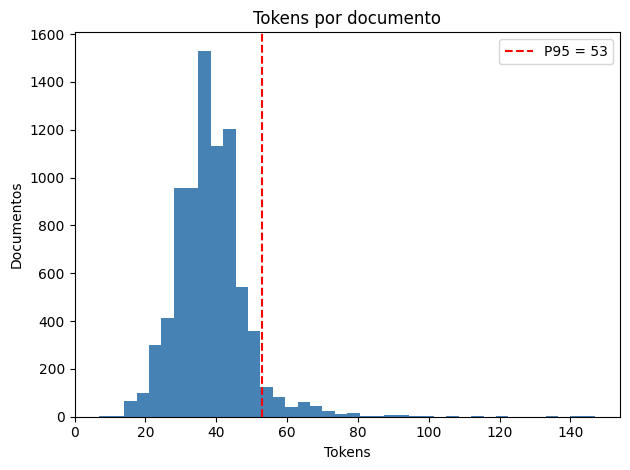

In [31]:
import matplotlib.pyplot as plt
import numpy as np

# Distribución de clases
train["label"].value_counts().plot(kind="bar", color="steelblue")
plt.title("Documentos por categoría (train)")
plt.ylabel("Cantidad")
plt.tight_layout()
plt.savefig("clases.png", dpi=150)
plt.show()

# Longitud en tokens
train["n_tokens"] = train["clean"].str.split().str.len()
p95 = int(np.percentile(train["n_tokens"], 95))
print("Percentil 95 (max_len):", p95)

plt.hist(train["n_tokens"], bins=40, color="steelblue")
plt.axvline(p95, color="red", linestyle="--", label=f"P95 = {p95}")
plt.title("Tokens por documento")
plt.xlabel("Tokens")
plt.ylabel("Documentos")
plt.legend()
plt.tight_layout()
plt.savefig("longitud.png", dpi=150)
plt.show()

In [32]:
from collections import Counter
from spacy.lang.en.stop_words import STOP_WORDS

palabras = Counter(" ".join(train["clean"]).split())
top50 = palabras.most_common(50)
n_stop = sum(1 for w, _ in top50 if w in STOP_WORDS)
print(f"{n_stop} de las 50 palabras más frecuentes son stop-words")
print(top50)

37 de las 50 palabras más frecuentes son stop-words
[('the', 13697), ('to', 7976), ('a', 7227), ('of', 6578), ('in', 6365), ('be', 4645), ('and', 4637), ('s', 4136), ('on', 3773), ('for', 3410), ('have', 2419), ('say', 1975), ('that', 1932), ('with', 1771), ('as', 1720), ('at', 1669), ('its', 1501), ('it', 1437), ('new', 1433), ('by', 1357), ('from', 1221), ('an', 1194), ('will', 1004), ('year', 968), ('after', 947), ('his', 940), ('over', 803), ('their', 733), ('up', 729), ('he', 727), ('two', 675), ('first', 673), ('company', 651), ('win', 622), ('world', 609), ('but', 598), ('one', 582), ('more', 578), ('they', 577), ('u', 571), ('game', 554), ('report', 551), ('us', 548), ('out', 545), ('this', 543), ('not', 531), ('1', 521), ('oil', 519), ('monday', 518), ('wednesday', 505)]


In [33]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

def top_ngrams(corpus, n, k=20):
    vec = CountVectorizer(ngram_range=(n, n), stop_words="english")
    X = vec.fit_transform(corpus)
    freqs = np.asarray(X.sum(axis=0)).ravel()
    idx = freqs.argsort()[::-1][:k]
    return pd.DataFrame({"ngrama": vec.get_feature_names_out()[idx],
                         "frecuencia": freqs[idx]})

bi = top_ngrams(train["clean"], 2)
tri = top_ngrams(train["clean"], 3)
print(bi)
print(tri)

             ngrama  frecuencia
0          new york         419
1         oil price         197
2     united states         167
3    prime minister         139
4      official say         131
5      say thursday         102
6        say monday         101
7       say tuesday          98
8           red sox          98
9     san francisco          96
10      los angeles          96
11   president bush          93
12    say wednesday          90
13         year old          88
14       say friday          88
15     mobile phone          72
16      wall street          71
17   microsoft corp          70
18        world cup          69
19  chief executive          67
                          ngrama  frecuencia
0                 boston red sox          37
1                 new york stock          37
2                 high oil price          27
3           prime minister ariel          26
4        canadian press canadian          26
5           press canadian press          26
6          mi

In [36]:
!pip install reportlab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 8.8 MB/s  0:00:00


In [38]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Separo 20% del train como validación (el test no se toca)
X_tr, X_val, y_tr, y_val = train_test_split(
    train["clean"], train["label"],
    test_size=0.2, stratify=train["label"], random_state=42)

# Combinaciones a probar: (max_features, ngram_range)
configs = [(5000, (1, 1)), (5000, (1, 2)),
           (20000, (1, 1)), (20000, (1, 2))]

for mf, ng in configs:
    vec = TfidfVectorizer(max_features=mf, ngram_range=ng, stop_words="english")
    Xa = vec.fit_transform(X_tr)   # fit SOLO con el train
    Xb = vec.transform(X_val)      # a la validación solo se le hace transform
    clf = LogisticRegression(max_iter=1000).fit(Xa, y_tr)
    acc = accuracy_score(y_val, clf.predict(Xb))
    print(f"max_features={mf}, ngram_range={ng} -> accuracy val: {acc:.4f}")

max_features=5000, ngram_range=(1, 1) -> accuracy val: 0.8881
max_features=5000, ngram_range=(1, 2) -> accuracy val: 0.8869
max_features=20000, ngram_range=(1, 1) -> accuracy val: 0.8900
max_features=20000, ngram_range=(1, 2) -> accuracy val: 0.8931


              precision    recall  f1-score   support

    Business       0.83      0.86      0.84       500
    Sci_Tech       0.88      0.87      0.87       500
      Sports       0.95      0.96      0.96       500
       World       0.91      0.88      0.90       500

    accuracy                           0.89      2000
   macro avg       0.89      0.89      0.89      2000
weighted avg       0.89      0.89      0.89      2000



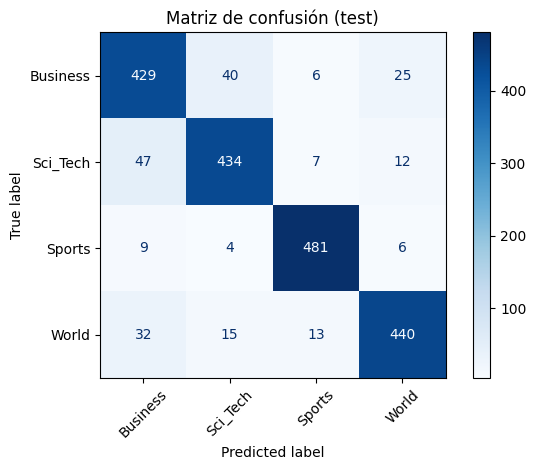

In [39]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Vectorizador con la mejor configuración
vec = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), stop_words="english")

# fit_transform SOLO en train; en test solo transform (evita data leakage)
X_train = vec.fit_transform(train["clean"])
X_test = vec.transform(test["clean"])

# Modelo final
clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, train["label"])

# Evaluación en el test
pred = clf.predict(X_test)
print(classification_report(test["label"], pred))

# Matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    test["label"], pred, cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión (test)")
plt.tight_layout()
plt.savefig("matriz_confusion.png", dpi=150)
plt.show()